# Task 59: Misclassification and Error Clusters

Manually inspect false positives and false negatives, cluster error examples with k-means, flag unusual feature values, and compare observed subgroup error counts.

Held-out metrics: {'accuracy': np.float64(0.8688524590163934), 'precision': np.float64(0.8787878787878788), 'recall': np.float64(0.8787878787878788), 'f1': np.float64(0.8787878787878788), 'TP': 29, 'TN': 24, 'FP': 4, 'FN': 4}
Misclassified examples: 8 FP: 4 FN: 4


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,Actual,Predicted,Probability,Error type
0,57,1,0,110,201,0,1,126,1,1.5,1,0,1,1,0,0.499,False negative
1,65,1,0,120,177,0,1,140,0,0.4,2,0,3,1,0,0.480,False negative
2,52,1,0,128,204,1,1,156,1,1.0,1,0,0,0,1,0.910,False positive
3,58,1,1,125,220,0,1,144,0,0.4,1,4,3,1,0,0.048,False negative
4,62,0,0,150,244,0,1,154,1,1.4,1,0,2,0,1,0.583,False positive
5,59,1,2,126,218,1,1,134,0,2.2,1,1,1,0,1,0.831,False positive
6,62,1,2,130,231,0,1,146,0,1.8,1,3,3,1,0,0.088,False negative
7,58,0,1,136,319,1,0,152,0,0.0,2,2,2,0,1,0.823,False positive


Error-case clusters; centers are standardized:


,count,false_positives,false_negatives
Cluster,,,
0,2,1,1
1,3,0,3
2,3,3,0


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,0.57,-0.47,-0.96,-0.09,-0.44,-0.40,0.95,-0.44,1.43,0.36,-0.64,-0.69,-1.38
1,0.80,0.63,-0.02,-0.37,-0.71,-0.40,0.95,-0.30,-0.70,-0.16,-0.11,1.70,1.16
2,0.22,-0.10,-0.02,-0.09,0.06,2.51,0.30,-0.12,0.01,0.02,-0.11,0.33,-2.23


Within-cluster squared distance: 48.918


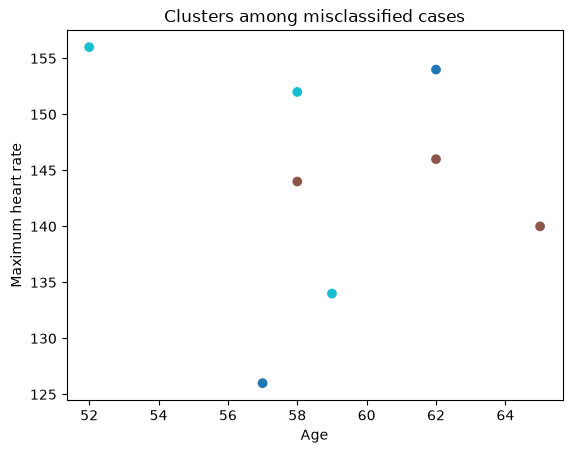

Error-case feature anomaly counts:


,Count beyond 2.5 SD
fbs,3
thal,1
ca,1
sex,0
age,0
chol,0
trestbps,0
cp,0
restecg,0
exang,0


Subgroup error counts:


,rows,FP,FN
sex,,,
0,27,2,0
1,34,2,4


,rows,FP,FN
Age band,,,
≤45,12,0,0
46–55,17,1,0
56–65,27,3,4
>65,5,0,0


Small subgroup error counts are exploratory; outliers and clusters require case review and cannot by themselves establish root cause.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

paths=[Path('heart.csv'),Path('Task_59_Misclassification_Cluster_Analysis/heart.csv'),Path('Heart_Disease_Tasks/Task_59_Misclassification_Cluster_Analysis/heart.csv')]
data=pd.read_csv(next(p for p in paths if p.is_file())).drop_duplicates().reset_index(drop=True)
features=[c for c in ['age','sex','cp','trestbps','chol','fbs','restecg','thalach','exang','oldpeak','slope','ca','thal'] if c in data]
X,y=data[features].to_numpy(float),data.target.to_numpy(int)

def stratified_split_indices(labels,fraction,seed):
    rng=np.random.default_rng(seed);a=[];b=[]
    for label in np.unique(labels):
        ids=np.flatnonzero(labels==label);rng.shuffle(ids);cut=round(fraction*len(ids));a.extend(ids[:cut]);b.extend(ids[cut:])
    rng.shuffle(a);rng.shuffle(b);return np.array(a),np.array(b)
train_idx,test_idx=stratified_split_indices(y,.8,59)
X_train,X_test,y_train,y_test=X[train_idx],X[test_idx],y[train_idx],y[test_idx]
mean,scale=X_train.mean(0),X_train.std(0);scale[scale==0]=1
X_train_scaled,X_test_scaled=(X_train-mean)/scale,(X_test-mean)/scale

class ManualLogistic:
    def fit(self,x,y):
        self.w=np.zeros(x.shape[1]);self.b=0.
        for _ in range(1400):
            p=1/(1+np.exp(-np.clip(x@self.w+self.b,-35,35)));e=p-y
            self.w-=.06*(x.T@e/len(y)+.02*self.w);self.b-=.06*e.mean()
        return self
    def proba(self,x):return 1/(1+np.exp(-np.clip(x@self.w+self.b,-35,35)))
model=ManualLogistic().fit(X_train_scaled,y_train)
probability=model.proba(X_test_scaled);prediction=(probability>=.5).astype(int)
fp=(y_test==0)&(prediction==1);fn=(y_test==1)&(prediction==0);errors=fp|fn

def evaluate(actual,pred):
    tp=np.sum((actual==1)&(pred==1));tn=np.sum((actual==0)&(pred==0));false_p=np.sum((actual==0)&(pred==1));false_n=np.sum((actual==1)&(pred==0))
    precision=tp/(tp+false_p) if tp+false_p else 0.;recall=tp/(tp+false_n) if tp+false_n else 0.
    return {'accuracy':(tp+tn)/len(actual),'precision':precision,'recall':recall,'f1':2*precision*recall/(precision+recall) if precision+recall else 0.,'TP':int(tp),'TN':int(tn),'FP':int(false_p),'FN':int(false_n)}
print('Held-out metrics:',evaluate(y_test,prediction))

# Manual Lloyd k-means on standardized error examples.
def manual_kmeans(points,k=3,seed=59,max_iterations=50):
    rng=np.random.default_rng(seed);centers=points[rng.choice(len(points),k,replace=False)].copy();labels=np.zeros(len(points),dtype=int)
    for _ in range(max_iterations):
        distances=np.sum((points[:,None,:]-centers[None,:,:])**2,axis=2);updated=np.argmin(distances,axis=1);new_centers=centers.copy()
        for cluster in range(k):
            members=points[updated==cluster]
            if len(members):new_centers[cluster]=members.mean(0)
        if np.array_equal(updated,labels) and np.allclose(new_centers,centers):break
        labels,centers=updated,new_centers
    inertia=np.sum((points-centers[labels])**2)
    return labels,centers,inertia

original_test=data.iloc[test_idx].reset_index(drop=True)
misclassified=original_test.loc[errors,features].copy().reset_index(drop=True)
misclassified['Actual']=y_test[errors];misclassified['Predicted']=prediction[errors];misclassified['Probability']=probability[errors]
misclassified['Error type']=np.where(fp[errors],'False positive','False negative')
print('Misclassified examples:',len(misclassified),'FP:',int(fp.sum()),'FN:',int(fn.sum()))
display(misclassified.head(15).round(3))

if len(misclassified)>=2:
    z=(misclassified[features].to_numpy(float)-mean)/scale;k=min(3,len(z));clusters,centers,inertia=manual_kmeans(z,k)
    misclassified['Cluster']=clusters
    summary=misclassified.groupby('Cluster').agg(count=('Error type','size'),false_positives=('Error type',lambda s:int((s=='False positive').sum())),false_negatives=('Error type',lambda s:int((s=='False negative').sum())))
    print('Error-case clusters; centers are standardized:');display(summary)
    display(pd.DataFrame(centers,columns=features).round(2))
    print('Within-cluster squared distance:',round(float(inertia),3))
    plt.scatter(misclassified['age'],misclassified['thalach'],c=clusters,cmap='tab10');plt.xlabel('Age');plt.ylabel('Maximum heart rate');plt.title('Clusters among misclassified cases');plt.show()

# Flag error cases beyond 2.5 training standard deviations for each numeric feature.
if len(misclassified):
    deviations=np.abs((misclassified[features].to_numpy(float)-mean)/scale)
    anomaly_counts=pd.Series((deviations>2.5).sum(0),index=features).sort_values(ascending=False)
    print('Error-case feature anomaly counts:');display(anomaly_counts.to_frame('Count beyond 2.5 SD'))

error_frame=original_test.copy();error_frame['Error type']=np.where(fp,'False positive',np.where(fn,'False negative','Correct'))
error_frame['Age band']=pd.cut(error_frame.age,[0,45,55,65,120],labels=['≤45','46–55','56–65','>65'])
print('Subgroup error counts:');display(error_frame.groupby('sex').agg(rows=('Error type','size'),FP=('Error type',lambda s:int((s=='False positive').sum())),FN=('Error type',lambda s:int((s=='False negative').sum()))))
display(error_frame.groupby('Age band',observed=False).agg(rows=('Error type','size'),FP=('Error type',lambda s:int((s=='False positive').sum())),FN=('Error type',lambda s:int((s=='False negative').sum()))))
print('Small subgroup error counts are exploratory; outliers and clusters require case review and cannot by themselves establish root cause.')

In [2]:

# Normalize subgroup error counts by the number of examples eligible for each error.
subgroup_frame=original_test.copy()
subgroup_frame['Actual']=y_test
subgroup_frame['Predicted']=prediction
subgroup_frame['Age band']=pd.cut(subgroup_frame.age,[0,45,55,65,120],labels=['<=45','46-55','56-65','>65'])
def rates_by_group(frame,column):
    rows=[]
    for key,part in frame.groupby(column,observed=False):
        actual=part.Actual.to_numpy();pred=part.Predicted.to_numpy();negative=actual==0;positive=actual==1
        fp=int(np.sum(negative&(pred==1)));fn=int(np.sum(positive&(pred==0)))
        rows.append({column:key,'rows':len(part),'FP':fp,'actual negatives':int(negative.sum()),'FPR':fp/negative.sum() if negative.any() else np.nan,'FN':fn,'actual positives':int(positive.sum()),'FNR':fn/positive.sum() if positive.any() else np.nan})
    return pd.DataFrame(rows).set_index(column)
print('Rate denominators are shown to distinguish group-size effects from different error rates.')
display(rates_by_group(subgroup_frame,'sex').round(3))
display(rates_by_group(subgroup_frame,'Age band').round(3))

Rate denominators are shown to distinguish group-size effects from different error rates.


,rows,FP,actual negatives,FPR,FN,actual positives,FNR
sex,,,,,,,
0,27,2,7,0.286,0,20,0.000
1,34,2,21,0.095,4,13,0.308


,rows,FP,actual negatives,FPR,FN,actual positives,FNR
Age band,,,,,,,
<=45,12,0,3,0.000,0,9,0.000
46-55,17,1,9,0.111,0,8,0.000
56-65,27,3,14,0.214,4,13,0.308
>65,5,0,2,0.000,0,3,0.000
